# Ramp frequency shift in the sideband phase calibration

$$J_\pm = e^{\mp i\,gt\,(a^\dagger\sigma_- + a\,\sigma_+)},\qquad R_z(\delta)=e^{-i\delta\sigma_z/2}$$

$R_z(\delta)$ = ramp Stark shift. It has the **same sign** after $J_+$ and after $J_-$ (it depends on ramp power, not on pulse phase).

$$U(N,\phi) = C(\phi)\;\big[R_z(\delta)\,J_-\,R_z(\delta)\,J_+\big]^{N}\;R_z(\delta)\;O$$

| case | start | open O | pairs $J_\pm$ | close C(φ) |
|---|---|---|---|---|
| 1 | $\lvert e,0\rangle$ | BS Q–C1 | Q–C1 | BS(φ) |
| 2 | $\lvert g,0\rangle$ | $R_x(\pi/2)$ | Q–C1 | $R_\phi(\pi/2)$ |
| 3 | $\lvert 0,e,0\rangle$ | BS Q–C1 | Q–C2 | BS(φ) |

BS: $gt=\pi/4$. Pairs: $gt=\pi/24$. Fit $P_e(\phi)=c+A\cos(\phi-\phi_0)$. Slope: $s=d\phi_0/dN$.

In [1]:
import numpy as np
from scipy.linalg import expm
import matplotlib.pyplot as plt

# ---------------- parameters ----------------
cav_dim   = 4                                   # cavity Fock truncation (single excitation is what matters)
gt_bs     = np.pi / 4                           # 50/50 beamsplitter
gt_small  = np.pi / 24                          # one small-angle Trotter step
deltas_deg = [0.0, 2.0, 5.0]                    # qubit phase per gap (degrees); 0 = reference
N_list    = np.arange(0, 9)                     # number of +/- pairs
phis      = np.linspace(0, 2 * np.pi, 41)[:-1]  # swept phase of the closing pulse
phi_fixed = 0.0                                 # phase for the P(e) vs N plot

## Operators

In [2]:
# single-mode operators
sm  = np.array([[0, 1], [0, 0]], dtype=complex)   # sigma_minus = |g><e|  (index 0 = g, 1 = e)
sz  = np.array([[-1, 0], [0, 1]], dtype=complex)  # sigma_z: +1 on e
sx  = np.array([[0, 1], [1, 0]], dtype=complex)
sy  = np.array([[0, -1j], [1j, 0]], dtype=complex)
Iq  = np.eye(2)
a   = np.diag(np.sqrt(np.arange(1, cav_dim)), 1).astype(complex)  # cavity lowering
Ic  = np.eye(cav_dim)

def kron(*ops):
    out = np.array([[1.0 + 0j]])
    for op in ops:
        out = np.kron(out, op)
    return out

def jc(gt, phi, a_full, sm_full):
    # resonant JC exchange between one cavity and the qubit
    H = np.exp(1j * phi) * a_full.conj().T @ sm_full + np.exp(-1j * phi) * a_full @ sm_full.conj().T
    return expm(-1j * gt * H)

def rz(delta, sz_full):
    # qubit-only Z rotation: the ramp frequency shift
    return expm(-1j * delta / 2 * sz_full)

def r_qubit(theta, phi, sx_full, sy_full):
    # qubit rotation by theta about the axis at angle phi in the xy plane
    return expm(-1j * theta / 2 * (np.cos(phi) * sx_full + np.sin(phi) * sy_full))

def fit_fringe(phis, p):
    # P = c0 + A cos(phi) + B sin(phi) = c0 + C cos(phi - phi0); linear least squares
    M = np.column_stack([np.ones_like(phis), np.cos(phis), np.sin(phis)])
    c0, A, B = np.linalg.lstsq(M, p, rcond=None)[0]
    return c0, np.hypot(A, B), np.arctan2(B, A)   # offset, amplitude, fringe phase phi0

## Sequence (the same list feeds the simulation and the diagram)

In [3]:
def build_sequence(case, delta, N, phi):
    # one dict per operation, in time order
    # kind: 'JC' (cavity 'C1'/'C2', gt, phase), 'Rq' (qubit rotation theta, phase), 'Rz' (qubit Z, delta)
    pair_cav = 'C2' if case == 3 else 'C1'
    ops = []
    if case == 2:
        ops.append(dict(kind='Rq', theta=np.pi / 2, phase=0.0, label='Rx(π/2)'))
    else:
        ops.append(dict(kind='JC', cav='C1', gt=gt_bs, phase=0.0, label='BS'))
    ops.append(dict(kind='Rz', delta=delta, label='Rz(δ)'))          # gap after opening pulse
    for k in range(N):
        ops.append(dict(kind='JC', cav=pair_cav, gt=gt_small, phase=0.0, label='JC(+gt)'))
        ops.append(dict(kind='Rz', delta=delta, label='Rz(δ)'))      # gap between + and -
        ops.append(dict(kind='JC', cav=pair_cav, gt=gt_small, phase=np.pi, label='JC(−gt)'))
        ops.append(dict(kind='Rz', delta=delta, label='Rz(δ)'))      # gap after the pair, SAME +delta
    if case == 2:
        ops.append(dict(kind='Rq', theta=np.pi / 2, phase=phi, label='Rφ(π/2)'))
    else:
        ops.append(dict(kind='JC', cav='C1', gt=gt_bs, phase=phi, label='BS(φ)'))
    return ops

# full-space operators: cases 1, 2 use q (x) c1; case 3 uses C1 (x) Q (x) C2
Pe_mat = np.diag([0, 1]).astype(complex)
ops_12 = dict(sz=kron(sz, Ic), sx=kron(sx, Ic), sy=kron(sy, Ic), sm=kron(sm, Ic),
              C1=kron(Iq, a), Pe=kron(Pe_mat, Ic))
ops_3 = dict(sz=kron(Ic, sz, Ic), sx=kron(Ic, sx, Ic), sy=kron(Ic, sy, Ic), sm=kron(Ic, sm, Ic),
             C1=kron(a, Iq, Ic), C2=kron(Ic, Iq, a), Pe=kron(Ic, Pe_mat, Ic))

psi_e0 = np.zeros(2 * cav_dim, complex); psi_e0[1 * cav_dim + 0] = 1                 # |e,0>
psi_g0 = np.zeros(2 * cav_dim, complex); psi_g0[0 * cav_dim + 0] = 1                 # |g,0>
psi_0e0 = np.zeros(cav_dim * 2 * cav_dim, complex); psi_0e0[1 * cav_dim + 0] = 1     # C1=0, Q=e, C2=0
psi_start = {1: psi_e0, 2: psi_g0, 3: psi_0e0}

def simulate(case, delta, N, phi):
    # apply the operation list to the start state; return P(e) and the final norm
    M = ops_3 if case == 3 else ops_12
    psi = psi_start[case].copy()
    for op in build_sequence(case, delta, N, phi):
        if op['kind'] == 'JC':
            U = jc(op['gt'], op['phase'], M[op['cav']], M['sm'])
        elif op['kind'] == 'Rq':
            U = r_qubit(op['theta'], op['phase'], M['sx'], M['sy'])
        else:
            U = rz(op['delta'], M['sz'])
        psi = U @ psi
    return np.real(psi.conj() @ M['Pe'] @ psi), np.linalg.norm(psi)

## Timeline, N = 2

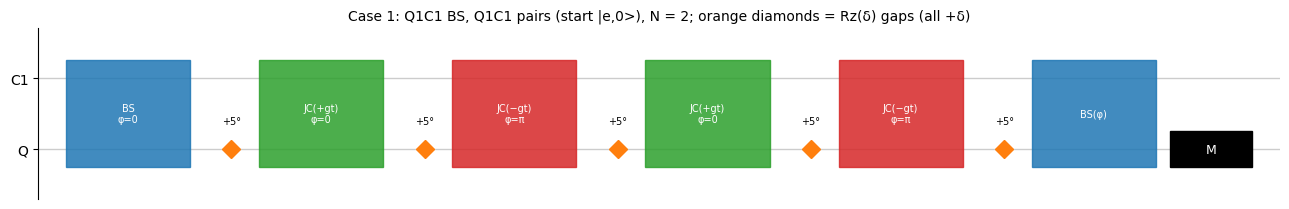

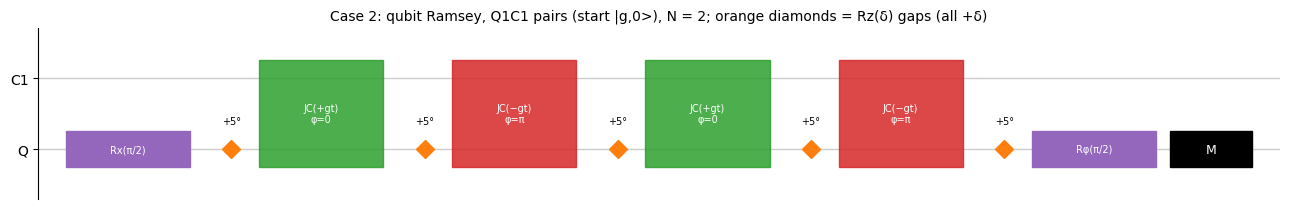

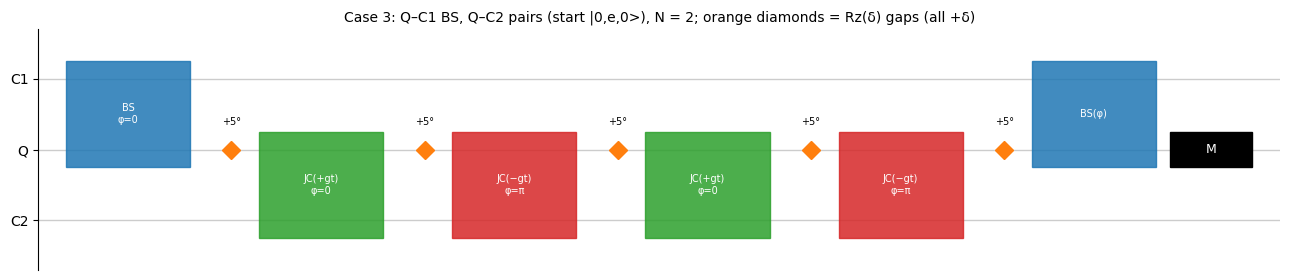

In [4]:
N_demo, delta_demo = 2, np.deg2rad(5.0)
mode_rows = {1: ['C1', 'Q'], 2: ['C1', 'Q'], 3: ['C1', 'Q', 'C2']}
titles = {1: 'Case 1: Q1C1 BS, Q1C1 pairs (start |e,0>)', 2: 'Case 2: qubit Ramsey, Q1C1 pairs (start |g,0>)',
          3: 'Case 3: Q–C1 BS, Q–C2 pairs (start |0,e,0>)'}
colors = {'BS': '#1f77b4', 'JC+': '#2ca02c', 'JC-': '#d62728', 'Rq': '#9467bd', 'Rz': '#ff7f0e'}

for case in [1, 2, 3]:
    ops = build_sequence(case, delta_demo, N_demo, phi=0.0)
    rows = mode_rows[case]
    y = {m: len(rows) - 1 - i for i, m in enumerate(rows)}     # top row first
    fig, ax = plt.subplots(figsize=(13, 0.8 + 0.7 * len(rows)))
    for m in rows:
        ax.axhline(y[m], color='0.8', lw=1, zorder=0)
    t = 0
    for i, op in enumerate(ops):
        last = (i == len(ops) - 1)
        if op['kind'] == 'JC':
            y0, y1 = sorted([y['Q'], y[op['cav']]])
            if op['gt'] == gt_bs:
                col, text = colors['BS'], ('BS(φ)' if last else 'BS\nφ=0')
            elif op['phase'] == 0:
                col, text = colors['JC+'], 'JC(+gt)\nφ=0'
            else:
                col, text = colors['JC-'], 'JC(−gt)\nφ=π'
            ax.add_patch(plt.Rectangle((t, y0 - 0.25), 0.9, y1 - y0 + 0.5, color=col, alpha=0.85))
            ax.text(t + 0.45, (y0 + y1) / 2, text, ha='center', va='center', fontsize=7, color='white')
            t += 1
        elif op['kind'] == 'Rq':
            ax.add_patch(plt.Rectangle((t, y['Q'] - 0.25), 0.9, 0.5, color=colors['Rq']))
            ax.text(t + 0.45, y['Q'], 'Rφ(π/2)' if last else 'Rx(π/2)', ha='center', va='center', fontsize=7, color='white')
            t += 1
        else:  # Rz gap marker
            ax.plot(t + 0.2, y['Q'], 'D', color=colors['Rz'], ms=9)
            ax.text(t + 0.2, y['Q'] + 0.35, f"+{np.degrees(op['delta']):.0f}°", ha='center', fontsize=7)
            t += 0.4
    ax.add_patch(plt.Rectangle((t, y['Q'] - 0.25), 0.6, 0.5, color='k'))
    ax.text(t + 0.3, y['Q'], 'M', ha='center', va='center', color='white', fontsize=9)
    ax.set_yticks([y[m] for m in rows]); ax.set_yticklabels(rows)
    ax.set_xlim(-0.2, t + 0.8); ax.set_ylim(-0.7, len(rows) - 0.3); ax.set_xticks([])
    ax.set_title(f'{titles[case]}, N = {N_demo}; orange diamonds = Rz(δ) gaps (all +δ)', fontsize=10)
    for s in ['top', 'right', 'bottom']:
        ax.spines[s].set_visible(False)
    fig.tight_layout()
    plt.show()

## Simulate

In [5]:
results = {}   # results[(case, delta_deg)] = dict(P=[N, phi], phase0=[N], amp=[N])
norm_err = 0.0
for case in [1, 2, 3]:
    for d_deg in deltas_deg:
        delta = np.deg2rad(d_deg)
        P = np.zeros((len(N_list), len(phis)))
        for i, N in enumerate(N_list):
            for j, phi in enumerate(phis):
                p, nrm = simulate(case, delta, N, phi)
                P[i, j] = p
                norm_err = max(norm_err, abs(nrm - 1))
        fits = [fit_fringe(phis, P[i]) for i in range(len(N_list))]
        phase0 = np.unwrap([f[2] for f in fits])
        amp = np.array([f[1] for f in fits])
        slope, icpt = np.polyfit(N_list, phase0, 1)
        results[(case, d_deg)] = dict(P=P, fits=fits, phase0=phase0, amp=amp, slope=slope, icpt=icpt)
print('max |norm - 1| over all runs:', norm_err)

max |norm - 1| over all runs: 1.4432899320127035e-15


## Approximate: one pair, in $\{\lvert e0\rangle,\lvert g1\rangle\}$

$$J_+=e^{-i\,gt\,\tau_x},\qquad J_-=J_+^\dagger,\qquad J_+^\dagger\,\tau_z\,J_+=\tau_z\cos 2gt+\tau_y\sin 2gt$$

$$R_z(\delta)\,J_-\,R_z(\delta)\,J_+ = e^{-i\frac{\delta}{2}\tau_z}\;e^{-i\frac{\delta}{2}(\tau_z\cos 2gt+\tau_y\sin 2gt)}
= e^{-i\,\delta\cos gt\,(\tau_z\cos gt+\tau_y\sin gt)}+O(\delta^2)$$

One pair is a rotation by $2\delta\cos gt$ about an axis tilted by $gt$ from z.

| | $s/2\delta$, short depth | $s/2\delta$, many turns |
|---|---|---|
| case 1 | $\cos^2 gt$ | $\cos gt$ |
| cases 2, 3 (one arm is a spectator) | $(1+\cos^2 gt)/2$ | $(1+\cos gt)/2$ |

In [6]:
gs = gt_small
print(f'gt_small = {np.degrees(gs):.3f} deg')
print(f'{"case":>4} {"delta(deg)":>10} {"fit slope(deg/pair)":>20} {"|slope|/delta":>14} {"analytic/delta":>15} {"contrast N=0":>13} {"contrast N=8":>13}')
for case in [1, 2, 3]:
    ana = 2 * np.cos(gs) ** 2 if case == 1 else 1 + np.cos(gs) ** 2
    for d_deg in deltas_deg:
        r = results[(case, d_deg)]
        ratio = abs(r['slope']) / np.deg2rad(d_deg) if d_deg > 0 else np.nan
        print(f'{case:>4} {d_deg:>10.1f} {np.degrees(r["slope"]):>20.5f} {ratio:>14.5f} {ana:>15.5f} '
              f'{r["amp"][0]:>13.5f} {r["amp"][-1]:>13.5f}')

gt_small = 7.500 deg
case delta(deg)  fit slope(deg/pair)  |slope|/delta  analytic/delta  contrast N=0  contrast N=8
   1        0.0              0.00000            nan         1.96593       0.50000       0.50000
   1        2.0              3.92865        1.96432         1.96593       0.50000       0.49989
   1        5.0              9.80222        1.96044         1.96593       0.50000       0.49691
   2        0.0              0.00000            nan         1.98296       0.50000       0.50000
   2        2.0             -3.96671        1.98335         1.98296       0.50000       0.49968
   2        5.0             -9.92627        1.98525         1.98296       0.50000       0.49826
   3        0.0              0.00000            nan         1.98296       0.50000       0.50000
   3        2.0              3.96671        1.98335         1.98296       0.50000       0.49968
   3        5.0              9.92627        1.98525         1.98296       0.50000       0.49826


## Checks

In [7]:
# 1. populations normalized (unitary evolution)
assert norm_err < 1e-12, norm_err
# 2. with delta = 0 the pairs are the identity: fringe phase independent of N (cases 1, 2 and also 3)
n_compared = 0
for case in [1, 2, 3]:
    ph = results[(case, 0.0)]['phase0']
    assert len(ph) == len(N_list)
    spread = np.max(np.abs(ph - ph[0]))
    print(f'case {case}, delta=0: compared {len(ph)} depths, max |phase(N) - phase(0)| = {spread:.2e} rad')
    assert spread < 1e-9, (case, spread)
    n_compared += len(ph)
# 3. ramp shift has the SAME sign in every gap (also around JC(-gt)): check the operation lists directly
n_rz = 0
for case in [1, 2, 3]:
    for d_deg in deltas_deg:
        for N in N_list:
            ops = build_sequence(case, np.deg2rad(d_deg), N, phi=0.3)
            rz_deltas = [op['delta'] for op in ops if op['kind'] == 'Rz']
            assert len(rz_deltas) == 2 * N + 1, (case, N, len(rz_deltas))
            assert all(d == np.deg2rad(d_deg) for d in rz_deltas), (case, d_deg, N)
            n_rz += len(rz_deltas)
print(f'Rz sign check: {n_rz} Rz gaps checked, all equal to +delta (2N+1 per sequence)')
# 3. every (case, delta) produced a full grid of points
for key, r in results.items():
    assert r['P'].shape == (len(N_list), len(phis)), key
print(f'all asserts passed: {n_compared} delta=0 depths compared, '
      f'{len(results)} (case, delta) grids of {len(N_list)} x {len(phis)} points')

case 1, delta=0: compared 9 depths, max |phase(N) - phase(0)| = 4.44e-16 rad
case 2, delta=0: compared 9 depths, max |phase(N) - phase(0)| = 0.00e+00 rad
case 3, delta=0: compared 9 depths, max |phase(N) - phase(0)| = 0.00e+00 rad
Rz sign check: 729 Rz gaps checked, all equal to +delta (2N+1 per sequence)
all asserts passed: 27 delta=0 depths compared, 9 (case, delta) grids of 9 x 40 points


## Fringes and fringe phase vs N

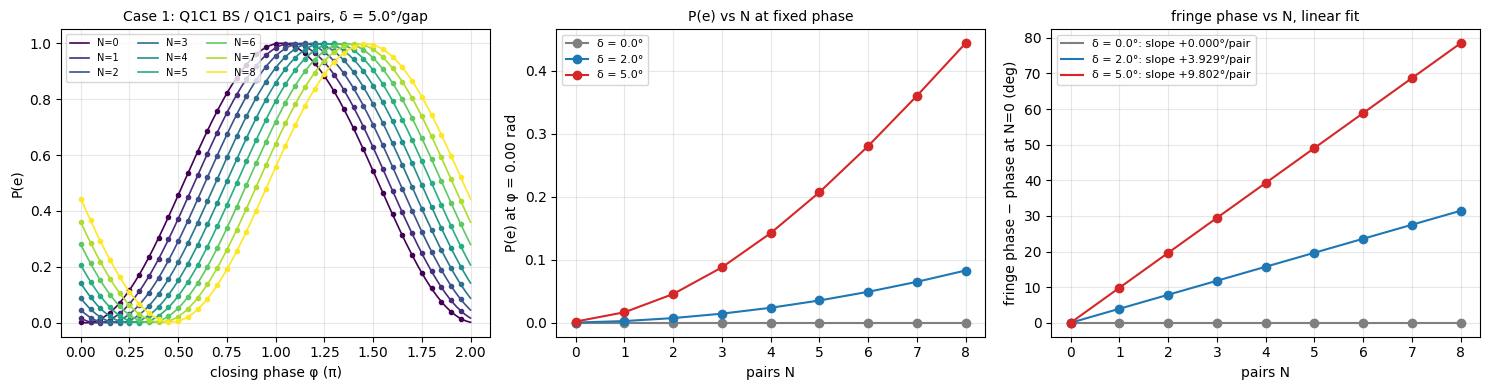

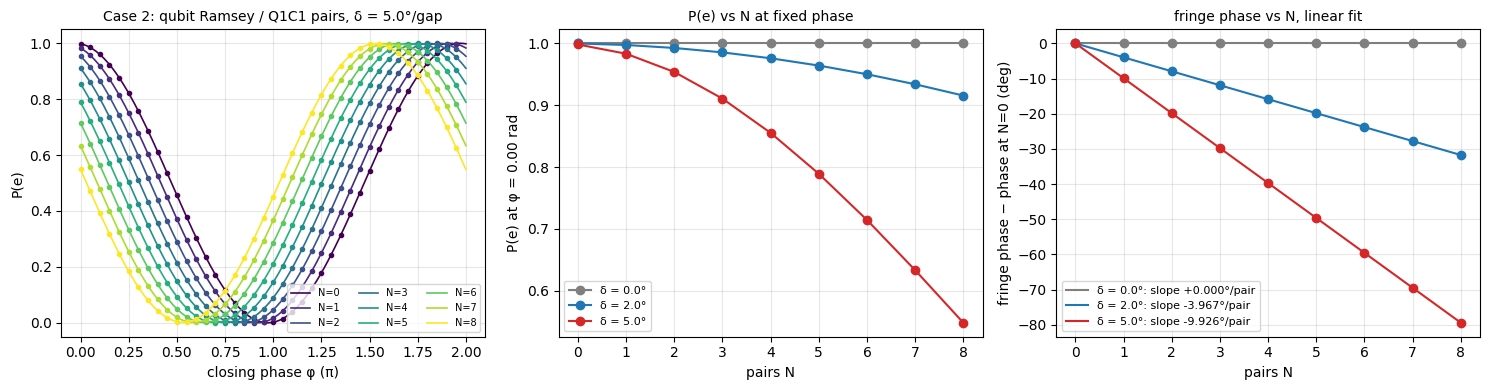

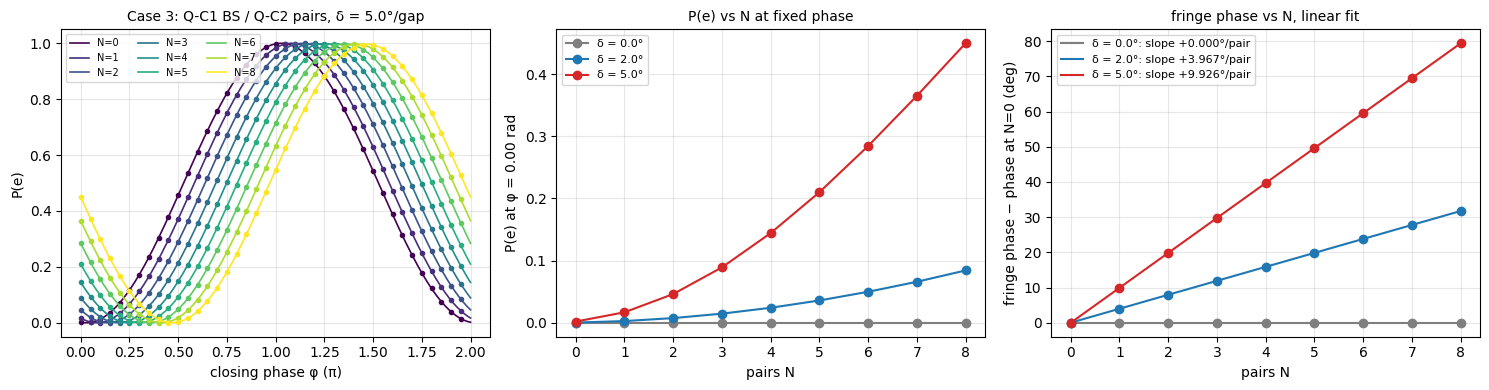

In [8]:
case_names = {1: 'Case 1: Q1C1 BS / Q1C1 pairs', 2: 'Case 2: qubit Ramsey / Q1C1 pairs',
              3: 'Case 3: Q-C1 BS / Q-C2 pairs'}
d_show = deltas_deg[-1]
cmap = plt.get_cmap('viridis')
delta_colors = ['#7f7f7f', '#1f77b4', '#d62728']   # fixed order: delta = 0, 2, 5 deg
phi_dense = np.linspace(0, 2 * np.pi, 200)
i_fixed = np.argmin(np.abs(phis - phi_fixed))

for case in [1, 2, 3]:
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    r = results[(case, d_show)]
    for i, N in enumerate(N_list):
        col = cmap(i / (len(N_list) - 1))
        c0, amp, ph0 = r['fits'][i]
        ax[0].plot(phis / np.pi, r['P'][i], 'o', ms=3, color=col)
        ax[0].plot(phi_dense / np.pi, c0 + amp * np.cos(phi_dense - ph0), '-', lw=1.2, color=col, label=f'N={N}')
    ax[0].set_xlabel('closing phase φ (π)'); ax[0].set_ylabel('P(e)')
    ax[0].set_title(f'{case_names[case]}, δ = {d_show}°/gap', fontsize=10)
    ax[0].legend(fontsize=7, ncol=3)

    for k, d_deg in enumerate(deltas_deg):
        rr = results[(case, d_deg)]
        ax[1].plot(N_list, rr['P'][:, i_fixed], 'o-', color=delta_colors[k], label=f'δ = {d_deg}°')
        ax[2].plot(N_list, np.degrees(rr['phase0'] - rr['phase0'][0]), 'o', color=delta_colors[k])
        ax[2].plot(N_list, np.degrees(rr['icpt'] - rr['phase0'][0] + rr['slope'] * N_list), '-', color=delta_colors[k],
                   label=f'δ = {d_deg}°: slope {np.degrees(rr["slope"]):+.3f}°/pair')
    ax[1].set_xlabel('pairs N'); ax[1].set_ylabel(f'P(e) at φ = {phis[i_fixed]:.2f} rad'); ax[1].legend(fontsize=8)
    ax[1].set_title('P(e) vs N at fixed phase', fontsize=10)
    ax[2].set_xlabel('pairs N'); ax[2].set_ylabel('fringe phase − phase at N=0 (deg)'); ax[2].legend(fontsize=8)
    ax[2].set_title('fringe phase vs N, linear fit', fontsize=10)
    for x in ax:
        x.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

## Result ($gt=\pi/24$, N = 0…8)

| case | δ = 2° | δ = 5° | $s/\delta$ (fit) | $s/\delta$ (formula) |
|---|---|---|---|---|
| 1 | +3.929°/pair | +9.802°/pair | 1.964 | $2\cos^2 gt$ = 1.966 |
| 2 | −3.967°/pair | −9.926°/pair | 1.983 | $1+\cos^2 gt$ = 1.983 |
| 3 | +3.967°/pair | +9.926°/pair | 1.983 | $1+\cos^2 gt$ = 1.983 |

$s\approx 2\delta$ per pair: the $J_+/J_-$ pair is not an echo for $R_z$. The sign of $s$ is only the closing pulse's phase convention.

# The correction

## Exact: a gap is a phase shift of every later pulse

$$R_z(D)\,J(\phi)\,R_z(-D)=J(\phi+D),\qquad R_z(D)\,R_\phi(\theta)\,R_z(-D)=R_{\phi-D}(\theta)$$

Shift pulse $k$ by $D_k=\delta\times(\text{gaps before }k)$:

$$U_{\text{corrected}}(N,\phi)=R_z\!\left(\textstyle\sum\delta\right)\,U_{\delta=0}(N,\phi)$$

The final $R_z$ does not change $P_e$. **δ per gap is the exact correction.**

In [9]:
# 1. A qubit Rz in a gap is EXACTLY a phase shift of every later pulse.
#    Check  Rz(D) U(phi) Rz(-D) = U(phi + s*D)  for every pulse type used here, and find the sign s.
D, phi_test = 0.37, 0.2
pulse_types = {
    'JC Q-C1 (cases 1, 2)': (ops_12, lambda p, M: jc(gt_small, p, M['C1'], M['sm'])),
    'JC Q-C1 (case 3)':     (ops_3,  lambda p, M: jc(gt_bs, p, M['C1'], M['sm'])),
    'JC Q-C2 (case 3)':     (ops_3,  lambda p, M: jc(gt_small, p, M['C2'], M['sm'])),
    'qubit R(pi/2)':        (ops_12, lambda p, M: r_qubit(np.pi / 2, p, M['sx'], M['sy'])),
}
frame_sign = {}
for name, (M, U) in pulse_types.items():
    lhs = rz(D, M['sz']) @ U(phi_test, M) @ rz(-D, M['sz'])
    err = {s: np.max(np.abs(lhs - U(phi_test + s * D, M))) for s in (+1, -1)}
    s = min(err, key=err.get)
    assert err[s] < 1e-12, (name, err)
    frame_sign[name] = s
    print(f'{name:22s}: Rz(D) U(phi) Rz(-D) = U(phi {"+" if s > 0 else "-"} D)   max error {err[s]:.1e}')
# The JC phase and the qubit-rotation phase are defined with opposite conventions, so their signs differ.
s_frame = {'JC': frame_sign['JC Q-C1 (cases 1, 2)'], 'Rq': frame_sign['qubit R(pi/2)']}
assert frame_sign['JC Q-C1 (case 3)'] == frame_sign['JC Q-C2 (case 3)'] == s_frame['JC']


def run_ops(case, ops):
    # same as simulate(), but takes an explicit operation list
    M = ops_3 if case == 3 else ops_12
    psi = psi_start[case].copy()
    for op in ops:
        if op['kind'] == 'JC':
            U = jc(op['gt'], op['phase'], M[op['cav']], M['sm'])
        elif op['kind'] == 'Rq':
            U = r_qubit(op['theta'], op['phase'], M['sx'], M['sy'])
        else:
            U = rz(op['delta'], M['sz'])
        psi = U @ psi
    return np.real(psi.conj() @ M['Pe'] @ psi)


def corrected_sequence(case, delta, N, phi, delta_corr):
    # The runtime's correction: every pulse gets an extra phase  s * (delta_corr x number of gaps before it).
    # The Rz(delta) gaps (the real ramp shift) stay in.  delta_corr = delta is the exact correction.
    ops, D_before = [], 0.0
    for op in build_sequence(case, delta, N, phi):
        if op['kind'] == 'Rz':
            D_before += delta_corr
            ops.append(op)
        else:
            ops.append(dict(op, phase=op['phase'] + s_frame[op['kind']] * D_before))
    return ops


# 2. Correcting with delta_corr = delta gives EXACTLY the delta = 0 fringes (the leftover Rz sits before the
#    measurement and P(e) does not see it). Checked at every N and phi of the main run.
d5 = np.deg2rad(deltas_deg[-1])
n_cmp, worst = 0, 0.0
for case in [1, 2, 3]:
    for N in N_list:
        for phi in phis:
            p_corr = run_ops(case, corrected_sequence(case, d5, N, phi, delta_corr=d5))
            p_ref = run_ops(case, build_sequence(case, 0.0, N, phi))
            worst = max(worst, abs(p_corr - p_ref))
            n_cmp += 1
assert n_cmp == 3 * len(N_list) * len(phis)
assert worst < 1e-12, worst
print(f'\nexact correction (delta_corr = delta = {deltas_deg[-1]} deg): compared {n_cmp} points against delta = 0, '
      f'max |P difference| = {worst:.1e}')


JC Q-C1 (cases 1, 2)  : Rz(D) U(phi) Rz(-D) = U(phi + D)   max error 2.2e-16
JC Q-C1 (case 3)      : Rz(D) U(phi) Rz(-D) = U(phi + D)   max error 3.6e-16
JC Q-C2 (case 3)      : Rz(D) U(phi) Rz(-D) = U(phi + D)   max error 2.2e-16
qubit R(pi/2)         : Rz(D) U(phi) Rz(-D) = U(phi - D)   max error 1.2e-16



exact correction (delta_corr = delta = 5.0 deg): compared 1080 points against delta = 0, max |P difference| = 2.9e-15


## The calibration writes $s/2$ per gap

$$s = 2\delta f,\quad f<1\ \Rightarrow\ \text{residual} = 2\delta(1-f)\ \text{per pair}\ (\text{measured again}\times f)$$

In [10]:
# 3. What the calibration actually does: it measures a slope s per pair and writes s/2 per gap.
#    s/2 is a little smaller than delta, so a residual walk is left. Fit it the same way as above.
print(f'delta = {deltas_deg[-1]} deg per gap, gt = {np.degrees(gt_small):.2f} deg, N = 0..{N_list[-1]}')
print(f'{"case":>4} {"measured |s|/2 (deg)":>21} {"= delta x":>10} {"residual slope (deg/pair)":>26} {"expected 2(delta - |s|/2)":>26}')
resid_slope = {}
for case in [1, 2, 3]:
    s_meas = abs(results[(case, deltas_deg[-1])]['slope'])
    dc = s_meas / 2
    ph = []
    for N in N_list:
        P = [run_ops(case, corrected_sequence(case, d5, N, phi, delta_corr=dc)) for phi in phis]
        ph.append(fit_fringe(phis, np.array(P))[2])
    slope = np.polyfit(N_list, np.unwrap(ph), 1)[0]
    resid_slope[case] = slope
    print(f'{case:>4} {np.degrees(dc):>21.4f} {dc / d5:>10.5f} {np.degrees(slope):>+26.4f} '
          f'{np.degrees(2 * (d5 - dc)):>26.4f}')


delta = 5.0 deg per gap, gt = 7.50 deg, N = 0..8
case  measured |s|/2 (deg)  = delta x  residual slope (deg/pair)  expected 2(delta - |s|/2)
   1                4.9011    0.98022                    +0.1944                     0.1978
   2                4.9631    0.99263                    -0.0731                     0.0737


   3                4.9631    0.99263                    +0.0731                     0.0737


## f depends on depth

Case 1: the state moves on a great circle tilted by $gt$:

$$\tan\phi_0=\cos gt\,\tan\psi,\qquad \psi = 2\delta\cos gt\;N$$

$$\left.\frac{d\phi_0}{dN}\right|_{N\to0}=2\delta\cos^2 gt,\qquad \overline{\frac{d\phi_0}{dN}}=2\delta\cos gt$$

Cases 2, 3: the spectator arm gets exactly δ per pair, and the $\lvert e\rangle$ arm gets $\delta\cos^2 gt$ (short depth) to $\delta\cos gt$ (many turns).

Top row: $\phi_0(N)/2\delta N$. Bottom row: contrast.

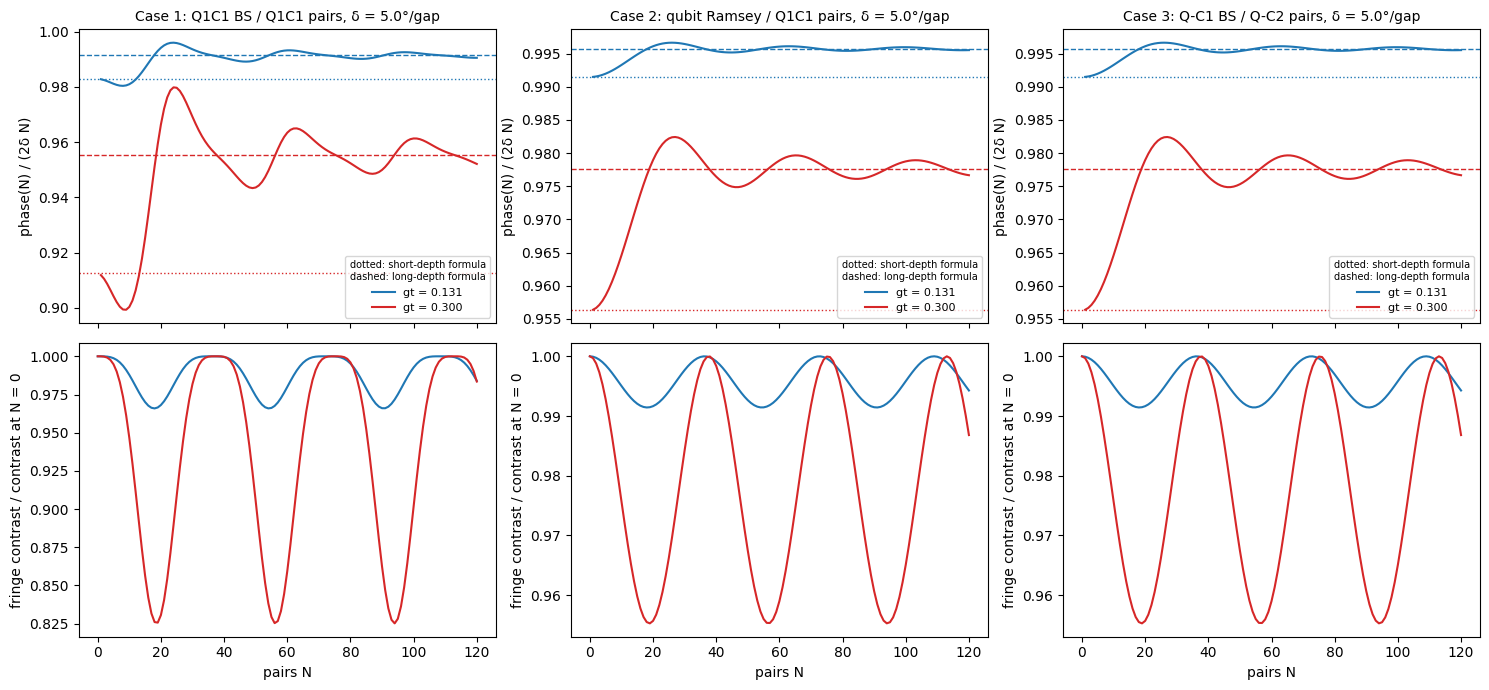

slope / (2 delta):
case     gt  short formula  fit N<=8  fit N<=120  long formula  min contrast
   1  0.131        0.98296   0.98022     0.99153       0.99144        0.9659
   1  0.300        0.91267   0.89892     0.95684       0.95534        0.8252
   2  0.131        0.99148   0.99263     0.99575       0.99572        0.9914
   2  0.300        0.95633   0.96150     0.97805       0.97767        0.9553
   3  0.131        0.99148   0.99263     0.99575       0.99572        0.9914
   3  0.300        0.95633   0.96150     0.97805       0.97767        0.9553


In [11]:
# 4. The short-depth slope (cos^2) is not the long-depth slope.
#    One pair = one rotation by 2 delta cos(gt) about an axis tilted gt away from z, so the fringe phase is NOT a
#    straight line in N: it wobbles around one. Run far enough to see several full turns (pair unitary applied
#    repeatedly; fringe phase from a closing-phase sweep and the same cosine fit as above).
phis_long = np.linspace(0, 2 * np.pi, 13)[:-1]
N_long = np.arange(0, 121)
gts_long = [gt_small, 0.3]                     # pi/24 (as above) and a larger angle where the effect is visible


def op_matrix(op, M, gt_pair):
    if op['kind'] == 'JC':
        gt = gt_pair if op['gt'] == gt_small else op['gt']    # only the small pair pulses change
        return jc(gt, op['phase'], M[op['cav']], M['sm'])
    if op['kind'] == 'Rq':
        return r_qubit(op['theta'], op['phase'], M['sx'], M['sy'])
    return rz(op['delta'], M['sz'])


def f_short(case, gt):
    # slope / (2 delta) at small depth
    return np.cos(gt) ** 2 if case == 1 else (1 + np.cos(gt) ** 2) / 2


def f_long(case, gt):
    # slope / (2 delta) averaged over many full turns
    return np.cos(gt) if case == 1 else (1 + np.cos(gt)) / 2


long_runs = {}
for case in [1, 2, 3]:
    M = ops_3 if case == 3 else ops_12
    for gt in gts_long:
        ops1 = build_sequence(case, d5, 1, 0.0)                # [open, gap, (+, gap, -, gap), close]
        U_open = op_matrix(ops1[1], M, gt) @ op_matrix(ops1[0], M, gt)
        U_pair = np.eye(len(psi_start[case]), dtype=complex)
        for op in ops1[2:6]:
            U_pair = op_matrix(op, M, gt) @ U_pair
        U_close = [op_matrix(build_sequence(case, d5, 0, phi)[-1], M, gt) for phi in phis_long]
        psi = U_open @ psi_start[case]
        ph, amp = [], []
        for N in N_long:
            P = [np.real((Uc @ psi).conj() @ M['Pe'] @ (Uc @ psi)) for Uc in U_close]
            c0, A, p0 = fit_fringe(phis_long, np.array(P))
            ph.append(p0); amp.append(A)
            psi = U_pair @ psi
        ph = np.unwrap(ph)
        long_runs[(case, gt)] = dict(phase=np.abs(ph - ph[0]), amp=np.array(amp))

fig, ax = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for k, case in enumerate([1, 2, 3]):
    for gt, col in zip(gts_long, ['#1f77b4', '#d62728']):
        r = long_runs[(case, gt)]
        ratio = r['phase'][1:] / (2 * d5 * N_long[1:])          # average slope so far, in units of 2 delta
        ax[0, k].plot(N_long[1:], ratio, '-', color=col, label=f'gt = {gt:.3f}')
        ax[0, k].axhline(f_short(case, gt), color=col, ls=':', lw=1)
        ax[0, k].axhline(f_long(case, gt), color=col, ls='--', lw=1)
        ax[1, k].plot(N_long, r['amp'] / r['amp'][0], '-', color=col)
    ax[0, k].set_title(f'{case_names[case]}, δ = {deltas_deg[-1]}°/gap', fontsize=10)
    ax[0, k].set_ylabel('phase(N) / (2δ N)')
    ax[1, k].set_ylabel('fringe contrast / contrast at N = 0')
    ax[1, k].set_xlabel('pairs N')
    ax[0, k].legend(fontsize=8, title='dotted: short-depth formula\ndashed: long-depth formula', title_fontsize=7)
fig.tight_layout()
plt.show()

print('slope / (2 delta):')
print(f'{"case":>4} {"gt":>6} {"short formula":>14} {"fit N<=8":>9} {"fit N<=120":>11} {"long formula":>13} {"min contrast":>13}')
for case in [1, 2, 3]:
    for gt in gts_long:
        r = long_runs[(case, gt)]
        s8 = np.polyfit(N_long[:9], r['phase'][:9], 1)[0] / (2 * d5)
        sall = np.polyfit(N_long, r['phase'], 1)[0] / (2 * d5)
        print(f'{case:>4} {gt:>6.3f} {f_short(case, gt):>14.5f} {s8:>9.5f} {sall:>11.5f} {f_long(case, gt):>13.5f} '
              f'{np.min(r["amp"] / r["amp"][0]):>13.4f}')
        assert abs(sall - f_long(case, gt)) < 0.01 * (1 - f_short(case, gt)) + 2e-3, (case, gt, sall)


## f at the CSWAP / Z2 angles

In [12]:
# 5. Size of the bias for the small-pulse angles used in the CSWAP / Z2 trains.
print('measured slope per pair = 2 delta x f;  f lies between its short-depth and long-depth value')
print(f'{"gt":>7} {"case 1 short":>13} {"case 1 long":>12} {"case 2/3 short":>15} {"case 2/3 long":>14} {"largest bias":>13}')
for gt in [0.0314159265, 0.106658621, gt_small]:
    print(f'{gt:>7.4f} {f_short(1, gt):>13.5f} {f_long(1, gt):>12.5f} {f_short(2, gt):>15.5f} {f_long(2, gt):>14.5f} '
          f'{100 * (1 - f_short(1, gt)):>12.2f}%')


measured slope per pair = 2 delta x f;  f lies between its short-depth and long-depth value
     gt  case 1 short  case 1 long  case 2/3 short  case 2/3 long  largest bias
 0.0314       0.99901      0.99951         0.99951        0.99975         0.10%
 0.1067       0.98867      0.99432         0.99433        0.99716         1.13%
 0.1309       0.98296      0.99144         0.99148        0.99572         1.70%


## Summary

* Correction model (δ per gap on every later pulse): **exact**.
* Measured $s/2 = \delta f$, so the shift is under-corrected by $1-f$:

| | f, short depth | f, many turns | $1-f$ at gt = 0.107 | $1-f$ at gt = 0.031 |
|---|---|---|---|---|
| case 1 | $\cos^2 gt$ | $\cos gt$ | ≤ 1.1 % | ≤ 0.1 % |
| cases 2, 3 | $(1+\cos^2 gt)/2$ | $(1+\cos gt)/2$ | ≤ 0.6 % | ≤ 0.05 % |

* Fix: divide $s$ by f.
* Not modelled: the shift during the flat top; $O(\delta^2)$ terms; more than one excitation.